# 03 — Accord du PID (S2-C02)

Le procédé est **instable en boucle ouverte** (pôle réel positif) : les méthodes classiques (Ziegler-Nichols en boucle ouverte, réponse indicielle) ne s'appliquent pas telles quelles. On compare :

1. **Ziegler-Nichols en boucle fermée** : gain ultime $K_u$ (limite d'oscillation) et période $P_u$ lus sur le modèle linéarisé, règles ZN-PID.
2. **Optimisation de marge** (assimilable à un placement de pôles) : gains minimisant l'abscisse spectrale de la boucle fermée linéarisée, puis vérification non linéaire.
3. **Gains retenus** pour l'application, validés en non linéaire (perturbation, échelons de consigne, anti-windup).

Convention du plan : erreur $e=T-T_{sp}$ (action inverse), sortie $u=u_{bias}+K_pe+K_iI+K_d\dot T_f$.

In [1]:
import sys, json
sys.path.insert(0, ".")
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
from scipy.integrate import solve_ivp

from cstr_model import (Params, Inputs, rhs, arrhenius, UA_eff, steady_states_level1,
                        jacobian_level1, R_GAS, p_sat_water, relief_heat)
from presets_py import seborg, propylene_oxide
from pid_sim import (Pid, closed_loop, linearize, steady_state_level2, closed_loop_spectral_abscissa,
                     search_gains, max_recoverable_perturbation, step_metrics)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
GOLDEN = Path("..") / "tests" / "golden"


In [2]:
p = seborg().with_(level=2)
v_nom = 0.3
xs = steady_state_level2(p, v_nom, [0.5, 350.0, 300.0, v_nom])
A, B = linearize(p, xs, v_nom)
print("Point de fonctionnement :", np.round(xs, 4))
print("Valeurs propres du procédé en boucle ouverte (s⁻¹) :", np.round(np.linalg.eigvals(A), 4))

Point de fonctionnement : [5.000000e-01 3.500025e+02 3.000009e+02 3.000000e-01]
Valeurs propres du procédé en boucle ouverte (s⁻¹) : [ 0.0119+0.j -0.0189+0.j -0.1332+0.j -0.5   +0.j]


## 1. Ziegler-Nichols en boucle fermée (P seul)

Pour un procédé instable, un régulateur P ne stabilise que dans une **fenêtre** $[K_{min},K_{max}]$ (en deçà de $K_{min}$ le pôle instable n'est pas dompté). $K_{max}$ joue le rôle de $K_u$ ; la pulsation d'oscillation donne $P_u=2\pi/\omega_u$.

In [3]:
def p_only(kp):
    n = A.shape[0]
    M = A.copy(); M[:, 1] += B * kp
    return np.linalg.eigvals(M)

kps = np.logspace(-3, 1.5, 2000)
stable = np.array([p_only(k).real.max() < 0 for k in kps])
Kmin, Kmax = kps[stable].min(), kps[stable].max()
ev = p_only(Kmax * 1.02)
osc = ev[np.argmax(ev.real)]
Ku, Pu = Kmax, 2 * np.pi / abs(osc.imag)
print(f"Fenêtre de stabilisation du P seul : K_p ∈ [{Kmin:.3f} ; {Kmax:.3f}]   (K_u ≈ {Ku:.3f}, P_u ≈ {Pu:.1f} s)")
zn = dict(kp=0.6 * Ku, ki=0.6 * Ku / (Pu / 2), kd=0.6 * Ku * Pu / 8)
print("ZN-PID : Kp = %.3f  Ki = %.4f  Kd = %.2f" % (zn["kp"], zn["ki"], zn["kd"]))

Fenêtre de stabilisation du P seul : K_p ∈ [0.012 ; 0.844]   (K_u ≈ 0.844, P_u ≈ 27.9 s)
ZN-PID : Kp = 0.507  Ki = 0.0364  Kd = 1.76


## 2. Optimisation de la marge de stabilité (linéaire) puis vérification non linéaire

In [4]:
best = search_gains(A, B, tau_f=2.0, kp_range=(-2, 1.0), ki_range=(-4, -0.5), kd_values=(0, 1, 3, 10), n=30)
print("Marge maximale (abscisse spectrale) = %.4f s⁻¹  pour Kp = %.3f  Ki = %.4f  Kd = %g" % best)

chosen = dict(kp=0.4, ki=0.01, kd=3.0)
candidates = {"ZN boucle fermée": zn,
              "Optimum linéaire": dict(kp=best[1], ki=best[2], kd=best[3]),
              "RETENU (preset)": chosen}
for name, g in candidates.items():
    m = closed_loop_spectral_abscissa(A, B, g["kp"], g["ki"], g["kd"], 2.0)
    print(f"{name:20s} Kp={g['kp']:.3f} Ki={g['ki']:.4f} Kd={g['kd']:.2f}   abscisse spectrale = {m:+.4f} s⁻¹")

Marge maximale (abscisse spectrale) = -0.0329 s⁻¹  pour Kp = 0.574  Ki = 0.0788  Kd = 3
ZN boucle fermée     Kp=0.507 Ki=0.0364 Kd=1.76   abscisse spectrale = -0.0322 s⁻¹
Optimum linéaire     Kp=0.574 Ki=0.0788 Kd=3.00   abscisse spectrale = -0.0329 s⁻¹
RETENU (preset)      Kp=0.400 Ki=0.0100 Kd=3.00   abscisse spectrale = -0.0266 s⁻¹


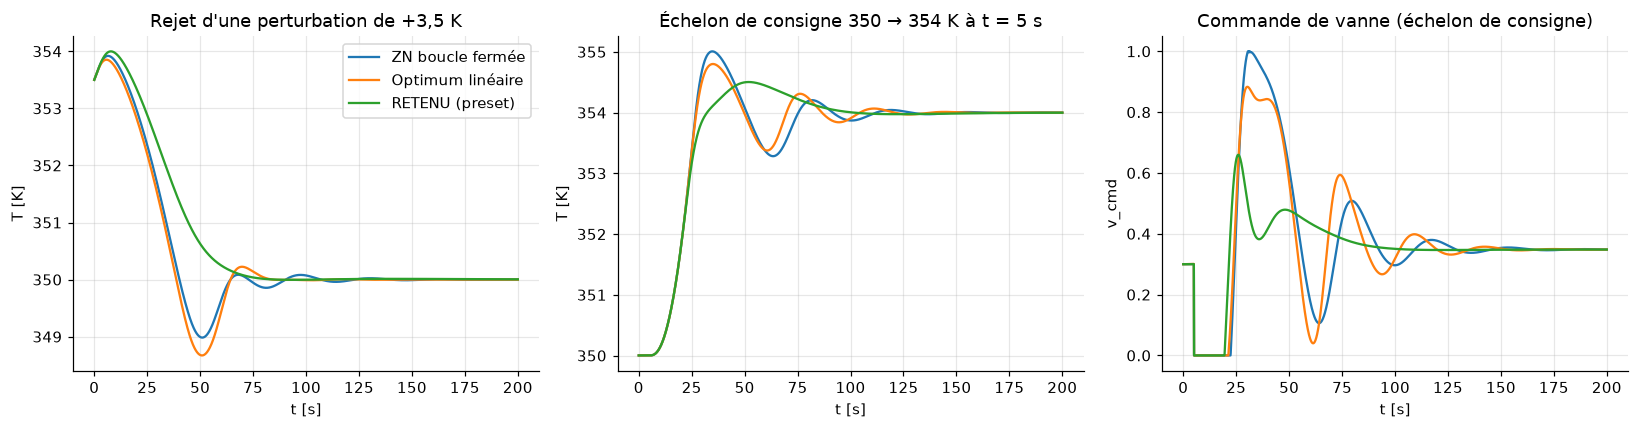

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name, g in candidates.items():
    pid = lambda sp=350.0: Pid(g["kp"], g["ki"], g["kd"], 2.0, v_nom, sp)
    t, X, V = closed_loop(p, [0.5, 353.5, 300.0, v_nom], pid(), t_end=200)
    axes[0].plot(t, X[1], label=name)
    t, X, V = closed_loop(p, list(xs), pid(), t_end=200, events=[(5, {"sp": 354.0})])
    axes[1].plot(t, X[1], label=name)
    axes[2].plot(t, V, label=name)
axes[0].set(title="Rejet d'une perturbation de +3,5 K", xlabel="t [s]", ylabel="T [K]")
axes[1].set(title="Échelon de consigne 350 → 354 K à t = 5 s", xlabel="t [s]", ylabel="T [K]")
axes[2].set(title="Commande de vanne (échelon de consigne)", xlabel="t [s]", ylabel="v_cmd")
axes[0].legend(); fig.tight_layout()

### Métriques comparées (simulation non linéaire)

In [6]:
rows = []
for name, g in candidates.items():
    pidf = lambda sp=350.0: Pid(g["kp"], g["ki"], g["kd"], 2.0, v_nom, sp)
    t, X, V = closed_loop(p, [0.5, 353.5, 300.0, v_nom], pidf(), t_end=300)
    e = np.abs(X[1] - 350.0)
    settle_pert = float(t[np.where(e > 0.5)[0][-1]]) if (e > 0.5).any() else 0.0
    iae = float(np.trapezoid(e, t))
    t2, X2, V2 = closed_loop(p, list(xs), pidf(), t_end=300, events=[(5, {"sp": 354.0})])
    over, settle_sp = step_metrics(t2, X2[1], 354.0, 5.0)
    dmax = max_recoverable_perturbation(p, xs, v_nom, (g["kp"], g["ki"], g["kd"]))
    rows.append((name, round(X[1].max() - 350, 2), round(settle_pert, 1), round(iae, 1),
                 round(over, 2), round(settle_sp, 1), round(float(V2.max()), 2), round(dmax, 1)))
pd.DataFrame(rows, columns=["gains", "pic ΔT perturb. [K]", "t réponse perturb. [s]", "IAE [K·s]",
                            "dépassement échelon [K]", "t réponse échelon [s]", "vanne max (échelon)",
                            "ΔT max rattrapable [K]"]).set_index("gains")

,pic ΔT perturb. [K],t réponse perturb. [s],IAE [K·s],dépassement échelon [K],t réponse échelon [s],vanne max (échelon),ΔT max rattrapable [K]
gains,,,,,,,
ZN boucle fermée,3.92,58.6,122.8,1.01,64.0,1.00,12.0
Optimum linéaire,3.85,60.3,122.9,0.80,59.3,0.88,12.0
RETENU (preset),4.00,52.5,139.9,0.50,48.5,0.66,12.0


**Lecture (mesures ci-dessus).** Les trois jeux de gains stabilisent le procédé et rattrapent la perturbation maximale testée (12 K, plafond de la bissection) : le ZN en boucle fermée appliqué à la fenêtre de stabilité du P seul donne ici un résultat convenable, avec la plus petite IAE (≈ 123 K·s). Les gains **retenus** sont les plus *doux* : dépassement d'échelon de consigne le plus faible (0,5 K contre ≈ 1 K) et sollicitation de vanne la plus modérée (pic 0,66 contre 1,00, c'est-à-dire sans saturation), au prix d'une IAE supérieure d'environ 14 %. On les retient pour préserver la marge d'autorité de la vanne et pour que la démonstration de l'anti-windup (§3) reste lisible : une saturation vient d'une vraie perte d'autorité, pas d'un réglage nerveux.

Les valeurs ZN sont à retenir comme point de comparaison ; l'équipe Génie Chimique pourra les substituer dans `SEBORG_PID`.

## 3. Anti-windup : avec / sans clamping

On impose une charge thermique excessive ($T_{in}=360$ K au lieu de 340 K) : la vanne sature. Quand la charge disparaît à $t=60$ s, un intégrateur *sans* anti-windup a accumulé une erreur (mesures ci-dessous : sans clamping, la vanne reste saturée ≈ 56 s au total (contre ≈ 3 s) et la température passe ≈ 1,9 K sous la consigne ; avec clamping, aucun sous-dépassement).

anti-windup ON  : vanne saturée   3.1 s ; T minimale après t = 60 s : 340.01 K ; écart max sous la consigne : -0.01 K
anti-windup OFF : vanne saturée  55.7 s ; T minimale après t = 60 s : 338.14 K ; écart max sous la consigne : +1.86 K


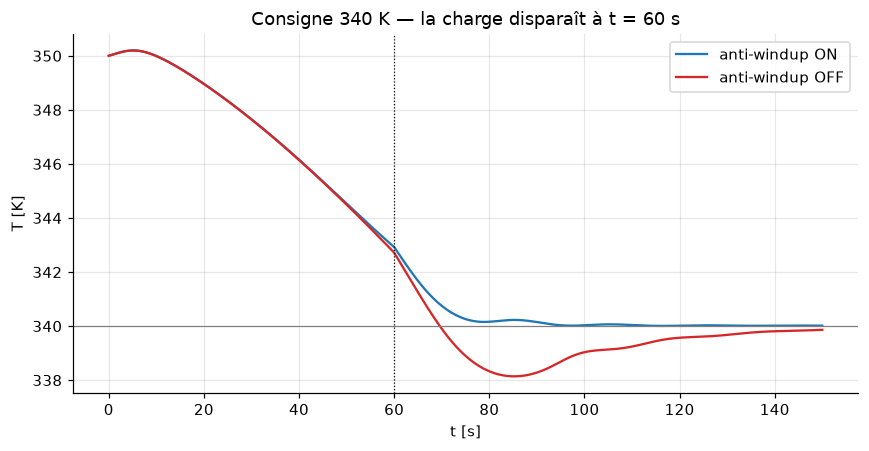

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.2))
results = {}
for aw, c in [(True, "tab:blue"), (False, "tab:red")]:
    pid = Pid(0.4, 0.01, 3.0, 2.0, v_nom, 340.0, anti_windup=aw)
    # T_in = 360 K (charge excessive) jusqu'à t = 60 s, puis retour à 340 K : une seule simulation continue
    t, X, V = closed_loop(p.with_(Tin=360.0), list(xs), pid, t_end=150,
                          events=[(60, {"params": {"Tin": 340.0}})])
    results[aw] = (t, X, V, pid)
    ax.plot(t, X[1], color=c, label=f"anti-windup {'ON' if aw else 'OFF'}")
ax.axvline(60, color="k", lw=0.8, ls=":"); ax.axhline(340, color="gray", lw=0.8)
ax.set(xlabel="t [s]", ylabel="T [K]", title="Consigne 340 K — la charge disparaît à t = 60 s"); ax.legend()
fig.tight_layout()
for aw, (t, X, V, pid) in results.items():
    after = t > 60
    sat = (V > 0.999)
    print(f"anti-windup {'ON ' if aw else 'OFF'} : vanne saturée {sat.sum() * 0.1:5.1f} s ; "
          f"T minimale après t = 60 s : {X[1][after].min():.2f} K ; "
          f"écart max sous la consigne : {340 - X[1][after].min():+.2f} K")

## 4. Valeurs retenues (reprises dans `presets/seborgBenchmark.ts`)

| Gain | Valeur | Unité |
| --- | --- | --- |
| $K_p$ | 0,4 | K⁻¹ |
| $K_i$ | 0,01 | K⁻¹·s⁻¹ |
| $K_d$ | 3 | s/K |
| $\tau_f$ | 2 | s |
| $u_{bias}$ | 0,3 | — |

Pour l'**oxyde de propylène** (procédé plus lent, autorité plus faible), la recherche linéaire donne un optimum vers $K_p\approx1{,}9$, $K_i\approx0{,}1$, $K_d\approx20$ (`PROPYLENE_OXIDE_PID`) : la perturbation de +1 K n'est rattrapée qu'après ≈ 300 s, vanne saturée plus de 200 s — la limite d'autorité de ce jeu est documentée ici.

PO — valeurs propres boucle ouverte (min⁻¹) : [  0.253+0.j  -0.291+0.j  -7.452+0.j -30.   +0.j]


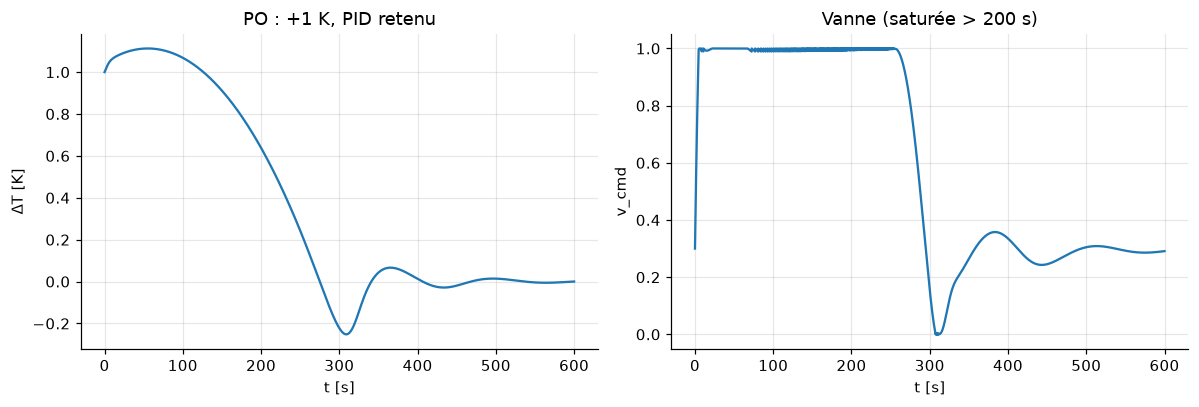

In [8]:
po = propylene_oxide()
ss1 = steady_states_level1(po.with_(level=1))[1]
xs_po = steady_state_level2(po, 0.3, [ss1[0], ss1[1], 285.0, 0.3])
A2, B2 = linearize(po, xs_po, 0.3)
print("PO — valeurs propres boucle ouverte (min⁻¹) :", np.round(np.linalg.eigvals(A2) * 60, 3))
t, X, V = closed_loop(po, [xs_po[0], xs_po[1] + 1.0, xs_po[2], 0.3], Pid(1.9, 0.1, 20, 2.0, 0.3, xs_po[1]), t_end=600)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(t, X[1] - xs_po[1]); axes[0].set(title="PO : +1 K, PID retenu", xlabel="t [s]", ylabel="ΔT [K]")
axes[1].plot(t, V); axes[1].set(title="Vanne (saturée > 200 s)", xlabel="t [s]", ylabel="v_cmd")
fig.tight_layout()